#
 — Modelado predictivo de producción de leche en vacas
**Proyecto de Machine Learning | Notebook reproducible para Google Colab**

## Objetivo general
Construir y comparar modelos que estimen `Milk_Yield_L` (regresión: litros de leche) usando las características disponibles antes de la predicción. Como la rúbrica también solicita clasificadores, se desarrolla un experimento complementario que clasifica la producción en niveles **bajo, medio y alto**. Ambos problemas se evalúan por separado.

### Métodos relacionados con los notebooks de clase
- **Clasificación:** Gaussian Naive Bayes, Decision Tree, Random Forest y SVM (`SVC`).
- **Regresión:** Decision Tree Regressor, Random Forest Regressor y Support Vector Regression (`SVR`).
- **Evaluación:** separación entrenamiento/prueba, validación cruzada, métricas de clasificación y regresión, análisis de sobreajuste y ajuste de hiperparámetros.
- **Deep learning:** red neuronal MLP con Keras como experimento complementario para atender la rúbrica.


## 0. Entorno y carga reproducible desde Google Drive

Para la carga del dataset, el archivo esté dentro de `Mi unidad/PROYECVACAS/` con exactamente ese nombre.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVR, SVC
from sklearn.neural_network import MLPClassifier

SEED = 21
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

ruta = "/content/drive/MyDrive/PROYECVACAS/global_cattle_milk_yield_prediction_dataset.csv"
if not os.path.exists(ruta):
    raise FileNotFoundError(
        f"No se encontró el archivo en: {ruta}\n"
        "Verifica el nombre del CSV y la carpeta PROYECVACAS en Google Drive."
    )

df = pd.read_csv(ruta)
print(f"Dataset cargado correctamente: {df.shape[0]:,} filas y {df.shape[1]} columnas")
display(df.head())

Mounted at /content/drive
Dataset cargado correctamente: 250,000 filas y 37 columnas


,Cattle_ID,Breed,Region,Country,Climate_Zone,Management_System,Age_Months,Weight_kg,Parity,Lactation_Stage,...,Anthrax_Vaccine,IBR_Vaccine,BVD_Vaccine,Rabies_Vaccine,Previous_Week_Avg_Yield,Body_Condition_Score,Milking_Interval_hrs,Date,Farm_ID,Milk_Yield_L
0,CATTLE_000001,Tharparkar,Africa,CA,Tropical,Intensive,32,259.9,4,Late,...,1,0,0,0,4.88,3.0,24,2023-02-06,FARM_0825,3.08
1,CATTLE_000002,Africander,South_America,ET,Arid,Semi_Intensive,63,593.9,6,Early,...,0,0,1,1,3.52,2.5,24,2022-10-31,FARM_0106,2.00
2,CATTLE_000003,Holstein-Friesian,Oceania,KE,Temperate,Intensive,132,675.4,3,Mid,...,1,0,1,0,11.28,2.5,12,2024-11-01,FARM_0201,14.06
3,CATTLE_000004,Fleckvieh,Europe_NA,BR,Tropical,Semi_Intensive,73,260.5,5,Late,...,0,0,0,0,10.63,4.0,8,2023-07-07,FARM_0174,12.74
4,CATTLE_000005,Danish_Red,Oceania,US,Subtropical,Extensive,50,477.8,6,Early,...,0,1,1,1,16.99,2.0,12,2024-09-20,FARM_0028,15.64


## 1. Auditoría de calidad y comprensión de los datos

Se revisan dimensiones, nombres, tipos, duplicados, valores faltantes y distribución de la variable objetivo. Esta auditoría ayuda a documentar las decisiones de preparación.

In [ ]:
TARGET = "Milk_Yield_L"
assert TARGET in df.columns, f"No existe la columna objetivo {TARGET}. Revisa df.columns."

print("Dimensiones:", df.shape)
print("\nTipos de datos:")
display(df.dtypes.astype(str).rename("tipo").to_frame())

print("\nValores faltantes por columna (mayores que cero):")
faltantes = df.isna().sum()
display(faltantes[faltantes > 0].sort_values(ascending=False).to_frame("faltantes"))

print("Filas duplicadas completas:", int(df.duplicated().sum()))
print("\nEstadísticos de la variable objetivo:")
display(df[TARGET].describe().to_frame().T)

print("Valores de producción negativos:", int((df[TARGET] < 0).sum()))

Dimensiones: (250000, 37)

Tipos de datos:


,tipo
Cattle_ID,object
Breed,object
Region,object
Country,object
Climate_Zone,object
Management_System,object
Age_Months,int64
Weight_kg,float64
Parity,int64
Lactation_Stage,object



Valores faltantes por columna (mayores que cero):


,faltantes


Filas duplicadas completas: 0

Estadísticos de la variable objetivo:


,count,mean,std,min,25%,50%,75%,max
Milk_Yield_L,250000.0,8.722596,5.763415,0.0,4.34,7.62,12.29,36.42


Valores de producción negativos: 0


### Decisiones de limpieza
- Se eliminan duplicados completos y filas sin variable objetivo.
- Los valores faltantes de las variables predictoras se imputan dentro de cada pipeline; así la imputación se aprende solo con entrenamiento.
- No se eliminan valores extremos de forma automática: primero se inspeccionan y se conservan salvo que exista una justificación de error de registro.
- `Cattle_ID` y `Farm_ID` se excluyen como predictores directos porque son identificadores, no características biológicas. `Farm_ID` se conserva solo para revisar la estructura de los datos.
- La variable `Date` se convierte en características de calendario (año, mes, día del año).
- `Previous_Week_Avg_Yield` solo se utiliza si realmente se conoce antes de estimar la producción del periodo objetivo. Se puede desactivar en el bloque de configuración.

In [ ]:
n_inicial = len(df)
df = df.drop_duplicates().copy()
df = df.dropna(subset=[TARGET]).copy()
df = df.loc[df[TARGET] >= 0].copy()

# Convertir fecha y derivar variables temporales sin utilizar la fecha como texto.
if "Date" in df.columns:
    fecha = pd.to_datetime(df["Date"], errors="coerce")
    df["Date_Year"] = fecha.dt.year
    df["Date_Month"] = fecha.dt.month
    df["Date_DayOfYear"] = fecha.dt.dayofyear
    df = df.drop(columns=["Date"])

print(f"Filas iniciales: {n_inicial:,}")
print(f"Filas después de limpieza básica: {len(df):,}")
print(f"Filas retiradas: {n_inicial - len(df):,}")

Filas iniciales: 250,000
Filas después de limpieza básica: 250,000
Filas retiradas: 0


## 2. Análisis exploratorio orientado al modelado

Estas gráficas sirven para describir la variable objetivo y explorar relaciones. Una asociación no demuestra causalidad.

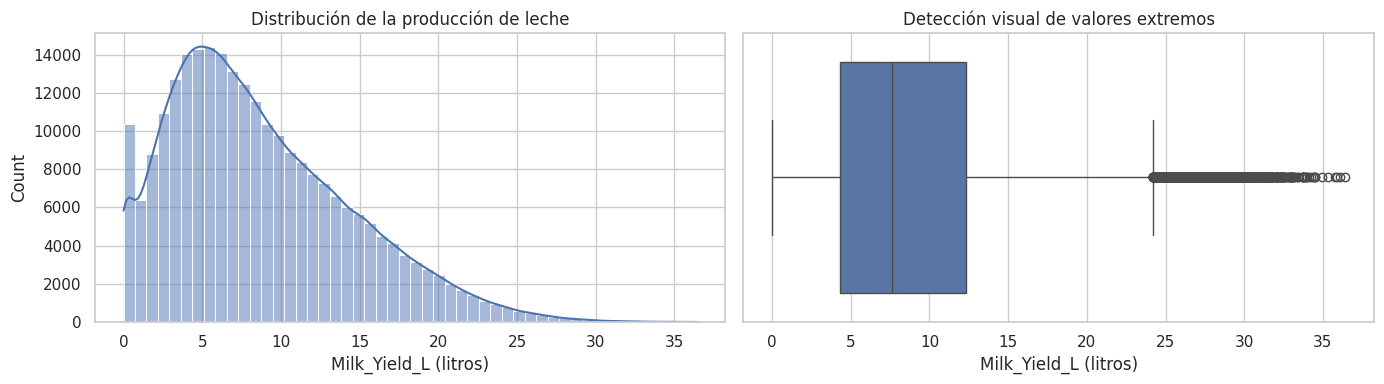

Media: 8.723
Mediana: 7.62
Desviación estándar: 5.763


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Distribución de la producción de leche")
ax[0].set_xlabel("Milk_Yield_L (litros)")
sns.boxplot(x=df[TARGET], ax=ax[1])
ax[1].set_title("Detección visual de valores extremos")
ax[1].set_xlabel("Milk_Yield_L (litros)")
plt.tight_layout()
plt.show()

print("Media:", round(df[TARGET].mean(), 3))
print("Mediana:", round(df[TARGET].median(), 3))
print("Desviación estándar:", round(df[TARGET].std(), 3))

In [ ]:
# Comparaciones exploratorias con variables que existen en el dataset.
for col in ["Breed", "Lactation_Stage", "Feed_Type", "Management_System"]:
    if col in df.columns:
        resumen = (df.groupby(col, observed=False)[TARGET]
                     .agg(["count", "mean", "median"])
                     .sort_values("mean", ascending=False))
        print(f"Producción por {col}")
        display(resumen.head(15))

Producción por Breed


,count,mean,median
Breed,,,
Holstein-Friesian,6227,17.513705,17.530
Brown_Swiss,6244,15.577774,15.610
Fleckvieh,6410,15.055144,15.100
Simmental,6196,15.021333,14.970
Norwegian_Red,6214,14.458659,14.470
Danish_Red,6422,13.762985,13.720
Ayrshire,6206,13.727931,13.690
Montbeliarde,6282,13.268890,13.250
Milking_Shorthorn,6119,13.099283,13.040


Producción por Lactation_Stage


,count,mean,median
Lactation_Stage,,,
Early,75059,9.892490,8.65
Mid,100008,8.981080,7.92
Late,74933,7.205754,6.38


Producción por Feed_Type


,count,mean,median
Feed_Type,,,
Silage,31079,8.742841,7.67
Concentrates,31282,8.742190,7.61
Green_Fodder,31222,8.732397,7.63
Pasture_Grass,31290,8.719910,7.64
Mixed_Feed,31151,8.719264,7.57
Hay,31134,8.714065,7.64
Crop_Residues,31273,8.708634,7.61
Dry_Fodder,31569,8.701753,7.58


Producción por Management_System


,count,mean,median
Management_System,,,
Semi_Intensive,49907,8.756937,7.66
Intensive,50322,8.718825,7.60
Extensive,49870,8.715567,7.62
Pastoral,50053,8.712126,7.60
Mixed,49848,8.709568,7.61


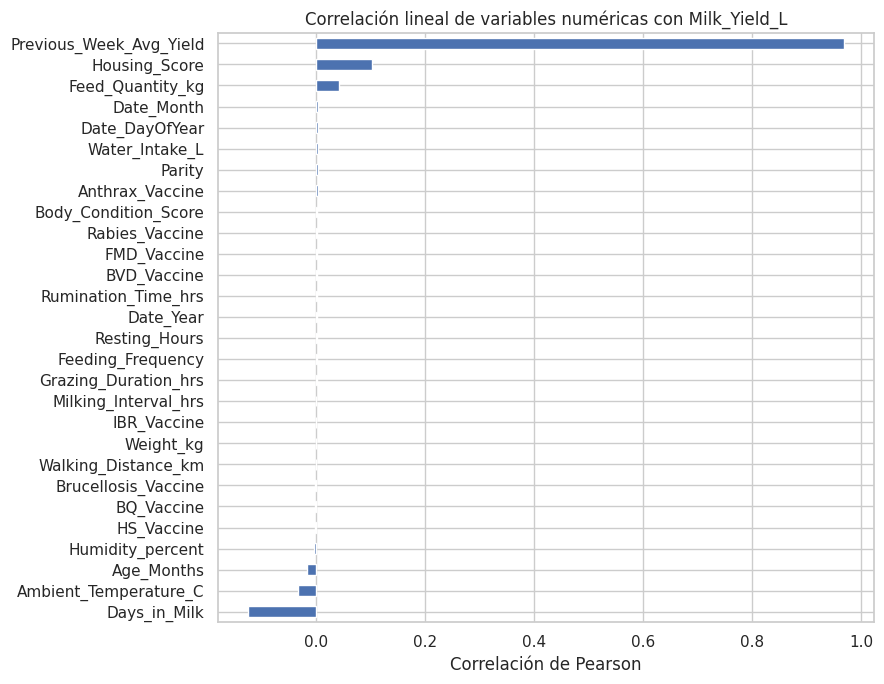

,correlacion_con_Milk_Yield_L
Days_in_Milk,-0.126380
Ambient_Temperature_C,-0.033068
Age_Months,-0.017587
Humidity_percent,-0.004679
HS_Vaccine,-0.002752
BQ_Vaccine,-0.002451
Brucellosis_Vaccine,-0.001888
Walking_Distance_km,-0.001117
Weight_kg,-0.000792
IBR_Vaccine,-0.000754


In [ ]:
# Correlaciones de variables numéricas con la producción.
num_cols_eda = df.select_dtypes(include=np.number).columns.tolist()
corr_target = df[num_cols_eda].corr(numeric_only=True)[TARGET].drop(TARGET).sort_values()
plt.figure(figsize=(9, max(5, len(corr_target) * 0.25)))
corr_target.plot(kind="barh")
plt.title("Correlación lineal de variables numéricas con Milk_Yield_L")
plt.xlabel("Correlación de Pearson")
plt.tight_layout()
plt.show()
display(corr_target.to_frame("correlacion_con_Milk_Yield_L"))

## 3. Definición de variables y protocolo de evaluación

**Problema principal:** regresión para estimar los litros de leche (`Milk_Yield_L`).

Se excluyen identificadores y la variable objetivo. `Previous_Week_Avg_Yield` se incluye inicialmente porque podría ser información histórica disponible antes de la predicción, pero se debe desactivar si en el uso real no estaría disponible. Se divide en 80% entrenamiento y 20% prueba con `random_state=21`, como semilla.

Para hacer las pruebas razonables en Colab, se limita el conjunto de modelado a un máximo configurable de filas, seleccionadas aleatoriamente y con semilla fija. El análisis exploratorio anterior usa el dataset limpio completo. Informa este límite en la exposición si el dataset supera el máximo.

In [ ]:
# CONFIGURACIÓN
MAX_FILAS_MODELADO = 60000   # Cambia a None para usar todas las filas; puede tardar más.
USAR_RENDIMIENTO_SEMANA_ANTERIOR = False

excluir = {TARGET, "Cattle_ID", "Farm_ID"}
if not USAR_RENDIMIENTO_SEMANA_ANTERIOR:
    excluir.add("Previous_Week_Avg_Yield")

# No usar columnas auxiliares identificadoras.
X_all = df.drop(columns=[c for c in excluir if c in df.columns]).copy()
y_all = df[TARGET].copy()

if MAX_FILAS_MODELADO is not None and len(X_all) > MAX_FILAS_MODELADO:
    X_model, _, y_model, _ = train_test_split(
        X_all, y_all, train_size=MAX_FILAS_MODELADO,
        random_state=SEED
    )
else:
    X_model, y_model = X_all.copy(), y_all.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model, test_size=0.20, random_state=SEED
)

print("Filas usadas para modelado:", len(X_model))
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Variables predictoras antes de codificar:", X_train.shape[1])
print("Objetivo:", TARGET)
print("¿Se usa Previous_Week_Avg_Yield?:", USAR_RENDIMIENTO_SEMANA_ANTERIOR)

Filas usadas para modelado: 60000
Entrenamiento: (48000, 35) | Prueba: (12000, 35)
Variables predictoras antes de codificar: 35
Objetivo: Milk_Yield_L
¿Se usa Previous_Week_Avg_Yield?: False


### Pipeline de preprocesamiento

El pipeline aplica imputación a numéricas y categóricas, codificación One-Hot a categorías y escalado a modelos sensibles a la escala (SVR/SVC/Naive Bayes/MLP). Los árboles y bosques no necesitan escalado, pero usar el mismo esquema de imputación y codificación mantiene el proceso ordenado. Al estar dentro del pipeline, los parámetros del preprocesamiento se ajustan únicamente con `X_train`.

In [ ]:
categoricas = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numericas = [c for c in X_train.columns if c not in categoricas]

preprocesador_arbol = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numericas),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categoricas)
    ],
    remainder="drop"
)

preprocesador_escalado = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numericas),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categoricas)
    ],
    remainder="drop"
)

print("Variables numéricas:", len(numericas))
print("Variables categóricas:", len(categoricas))
print("Numéricas:", numericas)
print("Categóricas:", categoricas)

Variables numéricas: 27
Variables categóricas: 8
Numéricas: ['Age_Months', 'Weight_kg', 'Parity', 'Days_in_Milk', 'Feed_Quantity_kg', 'Feeding_Frequency', 'Water_Intake_L', 'Walking_Distance_km', 'Grazing_Duration_hrs', 'Rumination_Time_hrs', 'Resting_Hours', 'Ambient_Temperature_C', 'Humidity_percent', 'Housing_Score', 'FMD_Vaccine', 'Brucellosis_Vaccine', 'HS_Vaccine', 'BQ_Vaccine', 'Anthrax_Vaccine', 'IBR_Vaccine', 'BVD_Vaccine', 'Rabies_Vaccine', 'Body_Condition_Score', 'Milking_Interval_hrs', 'Date_Year', 'Date_Month', 'Date_DayOfYear']
Categóricas: ['Breed', 'Region', 'Country', 'Climate_Zone', 'Management_System', 'Lactation_Stage', 'Feed_Type', 'Season']


## 4. Modelado principal: regresión para predecir litros

Se implementan los métodos del notebook de clase de regresión: `DecisionTreeRegressor`, `RandomForestRegressor` y `SVR`. Se evalúan con MAE, RMSE y R².

- **MAE:** error absoluto promedio, en litros; cuanto menor, mejor.
- **RMSE:** penaliza más los errores grandes, en litros; cuanto menor, mejor.
- **R²:** proporción de variabilidad explicada por el modelo; más cerca de 1 suele ser mejor. Puede ser negativo si el modelo predice peor que una referencia basada en la media.

In [ ]:
modelos_regresion = {
    "Decision Tree": Pipeline([
        ("prep", preprocesador_arbol),
        ("model", DecisionTreeRegressor(max_depth=15, min_samples_leaf=5, random_state=SEED))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocesador_arbol),
        ("model", RandomForestRegressor(
            n_estimators=150, max_depth=None, min_samples_leaf=2,
            n_jobs=-1, random_state=SEED
        ))
    ]),
    "SVR RBF": Pipeline([
        ("prep", preprocesador_escalado),
        ("model", SVR(kernel="rbf", C=10, epsilon=0.1))
    ])
}

resultados_reg = []
predicciones_reg = {}
for nombre, modelo in modelos_regresion.items():
    # SVR tiene coste computacional alto; se entrena con una muestra del entrenamiento.
    Xtr, ytr = X_train, y_train
    if nombre == "SVR RBF" and len(X_train) > 12000:
        Xtr, _, ytr, _ = train_test_split(
            X_train, y_train, train_size=12000, random_state=SEED
        )
        print(f"{nombre}: se ajusta con {len(Xtr):,} filas de entrenamiento por coste computacional.")
    inicio = time.time()
    modelo.fit(Xtr, ytr)
    pred = modelo.predict(X_test)
    predicciones_reg[nombre] = pred
    resultados_reg.append({
        "Modelo": nombre,
        "MAE_litros": mean_absolute_error(y_test, pred),
        "RMSE_litros": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "Segundos_entrenamiento_y_prediccion": round(time.time() - inicio, 2)
    })

resultados_reg = pd.DataFrame(resultados_reg).sort_values("RMSE_litros")
display(resultados_reg)

SVR RBF: se ajusta con 12,000 filas de entrenamiento por coste computacional.


,Modelo,MAE_litros,RMSE_litros,R2,Segundos_entrenamiento_y_prediccion
1,Random Forest,2.657388,3.467936,0.638562,280.30
2,SVR RBF,2.927864,3.785098,0.569429,106.14
0,Decision Tree,3.364034,4.310348,0.441638,2.01


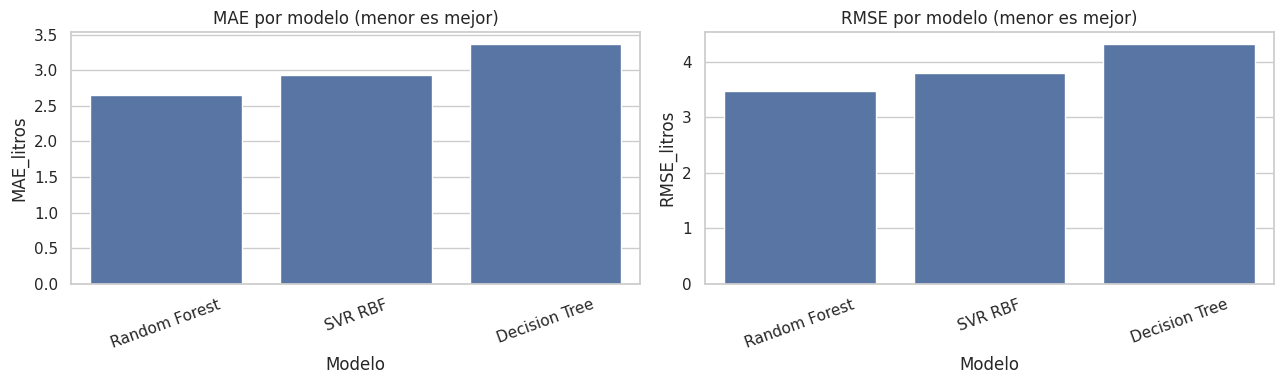

Mejor modelo según RMSE en prueba: Random Forest


In [ ]:
# Comparación gráfica de métricas (MAE/RMSE están en litros).
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=resultados_reg, x="Modelo", y="MAE_litros", ax=ax[0])
ax[0].set_title("MAE por modelo (menor es mejor)")
ax[0].tick_params(axis="x", rotation=20)
sns.barplot(data=resultados_reg, x="Modelo", y="RMSE_litros", ax=ax[1])
ax[1].set_title("RMSE por modelo (menor es mejor)")
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

mejor_reg_nombre = resultados_reg.iloc[0]["Modelo"]
mejor_reg = modelos_regresion[mejor_reg_nombre]
mejor_pred = predicciones_reg[mejor_reg_nombre]
print("Mejor modelo según RMSE en prueba:", mejor_reg_nombre)

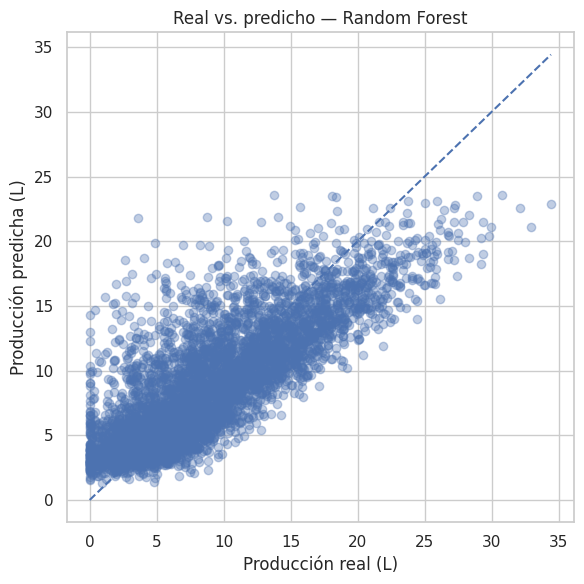

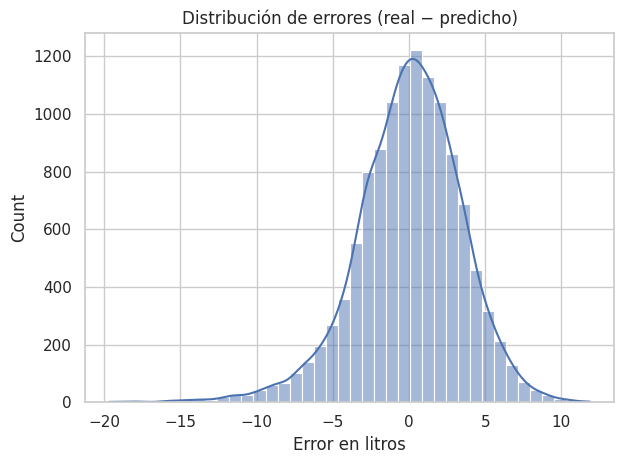

Error medio (sesgo aproximado): 0.003 litros


In [ ]:
# Real vs. predicho y distribución de errores del mejor modelo.
muestra_graf = min(5000, len(y_test))
rng = np.random.default_rng(SEED)
idx = rng.choice(len(y_test), size=muestra_graf, replace=False)
y_test_np = np.asarray(y_test)
pred_np = np.asarray(mejor_pred)

plt.figure(figsize=(6, 6))
plt.scatter(y_test_np[idx], pred_np[idx], alpha=0.35)
lim_inf = min(y_test_np[idx].min(), pred_np[idx].min())
lim_sup = max(y_test_np[idx].max(), pred_np[idx].max())
plt.plot([lim_inf, lim_sup], [lim_inf, lim_sup], linestyle="--")
plt.xlabel("Producción real (L)")
plt.ylabel("Producción predicha (L)")
plt.title(f"Real vs. predicho — {mejor_reg_nombre}")
plt.tight_layout()
plt.show()

errores = y_test_np - pred_np
sns.histplot(errores, bins=40, kde=True)
plt.title("Distribución de errores (real − predicho)")
plt.xlabel("Error en litros")
plt.tight_layout()
plt.show()
print("Error medio (sesgo aproximado):", round(float(np.mean(errores)), 3), "litros")

### Validación cruzada para el modelo de regresión seleccionado

La validación cruzada se aplica solo al conjunto de entrenamiento, para evitar utilizar el conjunto de prueba durante la selección. Por el coste de cálculo, se usa un subconjunto reproducible de hasta 20.000 filas y 5 particiones. La métrica `neg_root_mean_squared_error` se multiplica por -1 porque scikit-learn representa los errores como negativos en la función de puntuación.

In [ ]:
n_cv = min(20000, len(X_train))
X_cv, _, y_cv, _ = train_test_split(X_train, y_train, train_size=n_cv, random_state=SEED)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

modelo_cv = modelos_regresion[mejor_reg_nombre]
scores = cross_val_score(
    modelo_cv, X_cv, y_cv, cv=cv,
    scoring="neg_root_mean_squared_error", n_jobs=1
)
print("RMSE por fold:", np.round(-scores, 3))
print(f"RMSE promedio CV: {(-scores).mean():.3f} ± {scores.std():.3f} litros")

RMSE por fold: [3.59  3.579 3.516 3.509 3.475]
RMSE promedio CV: 3.534 ± 0.044 litros


## 5. Importancia de variables

Para los modelos basados en árboles, la importancia del bosque puede ayudar a explorar qué variables contribuyen más a las divisiones. Esta importancia es predictiva, no causal. Las variables categóricas aparecen divididas en categorías codificadas One-Hot.

,importancia
num__Days_in_Milk,0.082710
cat__Breed_Holstein-Friesian,0.058211
cat__Breed_Brown_Swiss,0.042366
cat__Breed_Fleckvieh,0.038990
cat__Breed_Simmental,0.038670
cat__Breed_Norwegian_Red,0.032035
cat__Lactation_Stage_Late,0.031923
cat__Breed_Ayrshire,0.031333
cat__Breed_Danish_Red,0.031070
num__Housing_Score,0.030732


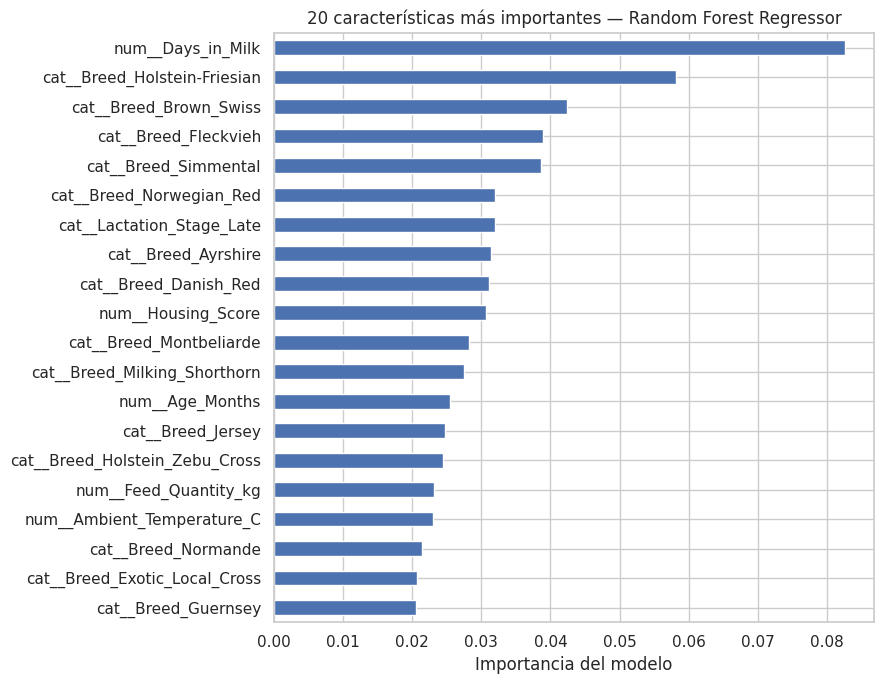

In [ ]:
rf_pipeline = modelos_regresion["Random Forest"]
rf_model = rf_pipeline.named_steps["model"]
prep_rf = rf_pipeline.named_steps["prep"]
try:
    nombres_transformados = prep_rf.get_feature_names_out()
    importancias = pd.Series(rf_model.feature_importances_, index=nombres_transformados)
    importancias = importancias.sort_values(ascending=False).head(20)
    display(importancias.to_frame("importancia"))
    importancias.sort_values().plot(kind="barh", figsize=(9, 7))
    plt.title("20 características más importantes — Random Forest Regressor")
    plt.xlabel("Importancia del modelo")
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("No fue posible recuperar nombres de características:", e)

## 6. Red neuronal profunda (MLP con Keras)

La rúbrica menciona deep learning. Este experimento usa una red neuronal con dos capas ocultas densas y regularización temprana (`EarlyStopping`). Se aplica al problema complementario de clasificación en tres niveles. El preprocesamiento se ajusta solo con entrenamiento. La red neuronal se incluye como comparación adicional, no se presupone que sea mejor que los modelos clásicos.

In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
MLP (Perceptrón Multicapa) de regresión para predecir la producción diaria
de leche de una vaca (Milk_Yield_L) a partir de datos tabulares.

Dataset : global_cattle_milk_yield_prediction_dataset.csv (250,000 registros)
Stack   : PyTorch + scikit-learn + pandas + numpy

Uso:
    python mlp_milk_yield.py
    python mlp_milk_yield.py --csv ruta/al/archivo.csv --epochs 150
"""

import argparse
import copy
import random
import warnings

import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, RobustScaler, StandardScaler
from torch.utils.data import DataLoader, TensorDataset

# 0. CONFIGURACIÓN GENERAL

CSV_PATH = "/content/drive/MyDrive/PROYECVACAS/global_cattle_milk_yield_prediction_dataset.csv"
SEED = 21

# --- Interruptor para un futuro modo de "pronóstico histórico" --------------
# False -> la red predice SOLO con características físicas/nutricionales/ambientales.
# True  -> añade `Previous_Week_Avg_Yield` (corr. ~0.97 con el objetivo: dependencia
#          autorregresiva / posible fuga de información).
INCLUDE_PREV_YIELD = False

# --- Escalador para variables numéricas: "standard" o "robust" 
NUMERIC_SCALER = "standard"

# --- Hiperparámetros 
HIDDEN_DIMS = [256, 128, 64]   # tamaño de cada capa oculta
DROPOUT = 0.2
ACTIVATION = "silu"            # "silu" o "relu"
BATCH_SIZE = 512
MAX_EPOCHS = 200
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
LOSS_NAME = "huber"            # "huber" o "mse"
ES_PATIENCE = 15               # épocas sin mejora antes de parar (EarlyStopping)
LR_PATIENCE = 5                # épocas sin mejora antes de reducir el LR
LR_FACTOR = 0.5
GRAD_CLIP = 5.0

TARGET = "Milk_Yield_L"

# --- Columnas 
NUMERIC_COLS = [
    "Age_Months", "Weight_kg", "Parity", "Days_in_Milk", "Feed_Quantity_kg",
    "Feeding_Frequency", "Water_Intake_L", "Walking_Distance_km",
    "Grazing_Duration_hrs", "Rumination_Time_hrs", "Resting_Hours",
    "Ambient_Temperature_C", "Humidity_percent", "Housing_Score",
    "Body_Condition_Score", "Milking_Interval_hrs",
]
BINARY_COLS = [
    "FMD_Vaccine", "Brucellosis_Vaccine", "HS_Vaccine", "BQ_Vaccine",
    "Anthrax_Vaccine", "IBR_Vaccine", "BVD_Vaccine", "Rabies_Vaccine",
]
CATEGORICAL_COLS = [
    "Breed", "Climate_Zone", "Management_System",
    "Lactation_Stage", "Feed_Type", "Season",
]

# Columnas EXCLUIDAS (documentadas; nunca entran al modelo):
#   Cattle_ID, Farm_ID, Date, Region, Country, Previous_Week_Avg_Yield*
#   (*salvo que INCLUDE_PREV_YIELD = True)
EXCLUDED_COLS = ["Cattle_ID", "Farm_ID", "Date", "Region", "Country"]
if not INCLUDE_PREV_YIELD:
    EXCLUDED_COLS.append("Previous_Week_Avg_Yield")
else:
    NUMERIC_COLS = NUMERIC_COLS + ["Previous_Week_Avg_Yield"]

FEATURES = NUMERIC_COLS + BINARY_COLS + CATEGORICAL_COLS


def set_seed(seed: int = SEED) -> None:
    """Fija semillas para reproducibilidad."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# 1. CARGA Y LIMPIEZA BÁSICA

def cargar_datos(csv_path: str) -> pd.DataFrame:
    """Carga el CSV, verifica columnas y elimina filas sin objetivo."""
    df = pd.read_csv(csv_path)
    print(f"[Datos] Registros cargados: {len(df):,} | Columnas: {df.shape[1]}")

    faltantes = [c for c in FEATURES + [TARGET] if c not in df.columns]
    if faltantes:
        raise ValueError(f"Faltan columnas requeridas en el CSV: {faltantes}")

    # Nos quedamos ÚNICAMENTE con las columnas permitidas (las excluidas se descartan).
    df = df[FEATURES + [TARGET]].copy()

    n_antes = len(df)
    df = df.dropna(subset=[TARGET]).reset_index(drop=True)
    if len(df) < n_antes:
        print(f"[Datos] Filas sin objetivo eliminadas: {n_antes - len(df):,}")

    print(f"[Datos] Variables predictoras usadas: {len(FEATURES)} "
          f"({len(NUMERIC_COLS)} numéricas, {len(BINARY_COLS)} binarias, "
          f"{len(CATEGORICAL_COLS)} categóricas)")
    return df

# 2. PREPROCESAMIENTO (se AJUSTA solo con Train)

def limpiar_binarias(X) -> np.ndarray:
    """
    Convierte las columnas binarias a 0/1 (float).
    Tolera valores tipo Yes/No, Sí/No, True/False, 1/0. Lo no reconocido -> NaN
    (luego se imputa con la moda del set de entrenamiento).
    Está definida a nivel de módulo para poder serializarla con joblib.
	"""
    X = pd.DataFrame(X).copy()
    mapa = {"yes": 1, "y": 1, "true": 1, "si": 1, "sí": 1, "1": 1, "1.0": 1,
            "no": 0, "n": 0, "false": 0, "0": 0, "0.0": 0}
    for c in X.columns:
        if pd.api.types.is_numeric_dtype(X[c]) or pd.api.types.is_bool_dtype(X[c]):
            X[c] = X[c].astype(float)
        else:
            X[c] = X[c].astype(str).str.strip().str.lower().map(mapa)
    return X.astype(float).values


def construir_preprocesador() -> ColumnTransformer:
    """ColumnTransformer: numéricas escaladas, binarias 0/1, categóricas One-Hot."""
    escalador = RobustScaler() if NUMERIC_SCALER == "robust" else StandardScaler()

    pipe_num = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", escalador),
    ])
    pipe_bin = Pipeline([
        ("limpieza", FunctionTransformer(limpiar_binarias, validate=False)),
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ])
    pipe_cat = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        # handle_unknown="ignore": categorías nuevas en inferencia -> vector de ceros
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer(
        transformers=[
            ("num", pipe_num, NUMERIC_COLS),
            ("bin", pipe_bin, BINARY_COLS),
            ("cat", pipe_cat, CATEGORICAL_COLS),
        ],
        remainder="drop",
    )

# 3. ARQUITECTURA DE LA RED

class MLPRegresor(nn.Module):
    """
    MLP tabular: [Linear -> BatchNorm1d -> Activación -> Dropout] x N -> Linear(1)
    """

    def __init__(self, in_dim: int, hidden_dims=HIDDEN_DIMS,
                 dropout: float = DROPOUT, activation: str = ACTIVATION):
        super().__init__()
        act = nn.SiLU if activation.lower() == "silu" else nn.ReLU

        capas, prev = [], in_dim
        for h in hidden_dims:
            capas += [nn.Linear(prev, h), nn.BatchNorm1d(h), act(), nn.Dropout(dropout)]
            prev = h
        capas.append(nn.Linear(prev, 1))  # salida lineal (regresión)
        self.red = nn.Sequential(*capas)

        self.apply(self._init_pesos)

    @staticmethod
    def _init_pesos(m):
        if isinstance(m, nn.Linear):
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.red(x).squeeze(-1)


# 4. ENTRENAMIENTO

class EarlyStopping:
    """Detiene el entrenamiento si la pérdida de validación no mejora."""

    def __init__(self, patience: int = ES_PATIENCE, min_delta: float = 1e-5):
        self.patience = patience
        self.min_delta = min_delta
        self.best = np.inf
        self.counter = 0
        self.best_state = None

    def step(self, val_loss: float, model: nn.Module) -> bool:
        if val_loss < self.best - self.min_delta:
            self.best = val_loss
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
        return self.counter >= self.patience  # True -> parar


def hacer_loader(X: np.ndarray, y: np.ndarray, shuffle: bool) -> DataLoader:
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32),
                       torch.tensor(y, dtype=torch.float32))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle,
                      drop_last=shuffle)  # drop_last evita lotes de 1 muestra (BatchNorm)


def evaluar_loss(model, loader, criterio, device) -> float:
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = criterio(model(xb), yb)
            total += loss.item() * len(xb)
            n += len(xb)
    return total / n


def entrenar(model, train_loader, val_loader, device, max_epochs=MAX_EPOCHS):
    criterio = nn.HuberLoss(delta=1.0) if LOSS_NAME == "huber" else nn.MSELoss()
    optimizador = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                                    weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizador, mode="min", factor=LR_FACTOR, patience=LR_PATIENCE)
    early = EarlyStopping()
    historial = {"train": [], "val": []}

    for epoca in range(1, max_epochs + 1):
        model.train()
        total, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizador.zero_grad()
            loss = criterio(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizador.step()
            total += loss.item() * len(xb)
            n += len(xb)

        train_loss = total / n
        val_loss = evaluar_loss(model, val_loader, criterio, device)
        scheduler.step(val_loss)
        historial["train"].append(train_loss)
        historial["val"].append(val_loss)

        lr_actual = optimizador.param_groups[0]["lr"]
        print(f"Época {epoca:03d} | train: {train_loss:.5f} | val: {val_loss:.5f} "
              f"| lr: {lr_actual:.2e}")

        if early.step(val_loss, model):
            print(f"[EarlyStopping] Sin mejora durante {ES_PATIENCE} épocas. "
                  f"Se detiene en la época {epoca}.")
            break

    # Restaurar los mejores pesos (menor pérdida en validación)
    if early.best_state is not None:
        model.load_state_dict(early.best_state)
        print(f"[Entrenamiento] Mejor pérdida de validación: {early.best:.5f}")
    return model, historial

# 5. EVALUACIÓN

def predecir_array(model, X: np.ndarray, device, y_mean: float, y_std: float) -> np.ndarray:
    """Predice en escala original (litros) a partir de una matriz ya preprocesada."""
    model.eval()
    salidas = []
    with torch.no_grad():
        for i in range(0, len(X), 4096):
            xb = torch.tensor(X[i:i + 4096], dtype=torch.float32, device=device)
            salidas.append(model(xb).cpu().numpy())
    return np.concatenate(salidas) * y_std + y_mean


def imprimir_metricas(nombre, y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    print(f"\n===== MÉTRICAS EN {nombre.upper()} =====")
    print(f"MAE  : {mae:.4f} litros")
    print(f"RMSE : {rmse:.4f} litros")
    print(f"R²   : {r2:.4f}")
    return mae, rmse, r2


def graficar_historial(historial, ruta="curvas_aprendizaje.png"):
    """Guarda la curva de aprendizaje (opcional; requiere matplotlib)."""
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        return
    plt.figure(figsize=(7, 4))
    plt.plot(historial["train"], label="Train")
    plt.plot(historial["val"], label="Validación")
    plt.xlabel("Época")
    plt.ylabel("Pérdida")
    plt.title("Curva de aprendizaje")
    plt.legend()
    plt.tight_layout()
    plt.savefig(ruta, dpi=120)
    plt.close()
    print(f"[Gráfico] Curva de aprendizaje guardada en: {ruta}")

# 6. INFERENCIA PARA UNA VACA NUEVA

# Estado global que se llena al terminar el entrenamiento (o al cargar artefactos)
_ESTADO = {"model": None, "prep": None, "y_mean": None, "y_std": None, "device": None}


def predecir_produccion(datos_vaca: dict) -> float:
    """
    Estima los litros de leche/día de una vaca nueva.

    Parámetros
    ----------
    datos_vaca : dict con las características de la vaca. Claves = nombres de
                 las 30 variables predictoras (ver NUMERIC_COLS, BINARY_COLS y
                 CATEGORICAL_COLS). Las claves ausentes se imputan con la
                 mediana/moda del set de entrenamiento (se emite una advertencia).

    Retorna
    -------
    float : producción estimada en litros.
    """
    if _ESTADO["model"] is None:
        raise RuntimeError("El modelo no está listo. Entrena primero o llama a cargar_artefactos().")

    faltantes = [c for c in FEATURES if c not in datos_vaca]
    if faltantes:
        warnings.warn(f"Variables ausentes (se imputarán): {faltantes}")

    df = pd.DataFrame([datos_vaca]).reindex(columns=FEATURES)
    X = _ESTADO["prep"].transform(df)
    pred = predecir_array(_ESTADO["model"], X, _ESTADO["device"],
                          _ESTADO["y_mean"], _ESTADO["y_std"])[0]
    return float(max(pred, 0.0))  # la producción de leche no puede ser negativa


def guardar_artefactos(model, prep, y_mean, y_std, in_dim, ruta="modelo_leche.pt"):
    """Guarda pesos + preprocesador + estadísticas del objetivo."""
    torch.save({"state_dict": model.state_dict(), "in_dim": in_dim,
                "y_mean": y_mean, "y_std": y_std,
                "hidden_dims": HIDDEN_DIMS, "dropout": DROPOUT,
                "activation": ACTIVATION, "features": FEATURES}, ruta)
    joblib.dump(prep, "preprocesador_leche.joblib")
    print(f"[Guardado] {ruta} y preprocesador_leche.joblib")


def cargar_artefactos(ruta="modelo_leche.pt", ruta_prep="preprocesador_leche.joblib"):
    """Recarga el modelo para usar predecir_produccion() sin reentrenar."""
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(ruta, map_location=device, weights_only=False)
    model = MLPRegresor(ckpt["in_dim"], ckpt["hidden_dims"], ckpt["dropout"],
                        ckpt["activation"]).to(device)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    _ESTADO.update(model=model, prep=joblib.load(ruta_prep),
                   y_mean=ckpt["y_mean"], y_std=ckpt["y_std"], device=device)
    print("[Carga] Modelo y preprocesador listos.")


# 7. PIPELINE PRINCIPAL

def main(csv_path: str, max_epochs: int):
    set_seed()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"[Sistema] Dispositivo: {device}")
    if INCLUDE_PREV_YIELD:
        print("[Aviso] INCLUDE_PREV_YIELD=True: modo de pronóstico histórico (riesgo de fuga).")

    # ---- 1) Datos ------------------------------------------------------------
    df = cargar_datos(csv_path)
    X_df, y = df[FEATURES], df[TARGET].values.astype(np.float64)

    # ---- 2) Split 70 / 15 / 15 ANTES de ajustar escaladores/codificadores ----
    X_train, X_temp, y_train, y_temp = train_test_split(
        X_df, y, test_size=0.30, random_state=SEED)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=SEED)
    print(f"[Split] Train: {len(X_train):,} | Val: {len(X_val):,} | Test: {len(X_test):,}")

    # ---- 3) Preprocesamiento: fit SOLO con Train -----------------------------
    prep = construir_preprocesador()
    Xtr = prep.fit_transform(X_train)
    Xva = prep.transform(X_val)
    Xte = prep.transform(X_test)
    in_dim = Xtr.shape[1]
    print(f"[Preprocesamiento] Dimensión de entrada tras One-Hot: {in_dim}")

    # Estandarizar el objetivo con estadísticas de Train (estabiliza el entrenamiento)
    y_mean, y_std = float(y_train.mean()), float(y_train.std())
    ytr_s = (y_train - y_mean) / y_std
    yva_s = (y_val - y_mean) / y_std

    # ---- 4) Modelo y entrenamiento --------------------------------------------
    model = MLPRegresor(in_dim).to(device)
    print(model)
    print(f"[Modelo] Parámetros entrenables: "
          f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

    train_loader = hacer_loader(Xtr, ytr_s, shuffle=True)
    val_loader = hacer_loader(Xva, yva_s, shuffle=False)
    model, historial = entrenar(model, train_loader, val_loader, device, max_epochs)
    graficar_historial(historial)

    # ---- 5) Evaluación (en litros) -------------------------------------------
    imprimir_metricas("validación", y_val, predecir_array(model, Xva, device, y_mean, y_std))
    imprimir_metricas("prueba (test)", y_test, predecir_array(model, Xte, device, y_mean, y_std))

    # ---- 6) Dejar listo el estado para inferencia y guardar ------------------
    _ESTADO.update(model=model, prep=prep, y_mean=y_mean, y_std=y_std, device=device)
    guardar_artefactos(model, prep, y_mean, y_std, in_dim)

    # ---- 7) Demostración de predecir_produccion() ----------------------------
    ejemplo = X_test.iloc[0].to_dict()
    real = float(y_test[0])
    estimado = predecir_produccion(ejemplo)
    print("\n===== EJEMPLO DE INFERENCIA =====")
    print(f"Vaca de ejemplo: {ejemplo}")
    print(f"Producción real     : {real:.2f} L")
    print(f"Producción estimada : {estimado:.2f} L")


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="MLP para predecir Milk_Yield_L")
    parser.add_argument("--csv", default=CSV_PATH, help="Ruta al archivo CSV")
    parser.add_argument("--epochs", type=int, default=MAX_EPOCHS, help="Máximo de épocas")
    # parse_known_args para ignorar argumentos específicos de Colab
    args, unknown = parser.parse_known_args()
    main(args.csv, args.epochs)


## 7. Aprendizaje no supervisado


¡Dataset cargado con éxito desde sample_data! Dimensiones: 250,000 filas, 40 columnas.

--- Distribución de Clústeres K-Means ---
Cluster
2    97399
1    92525
0    60076
Name: count, dtype: int64


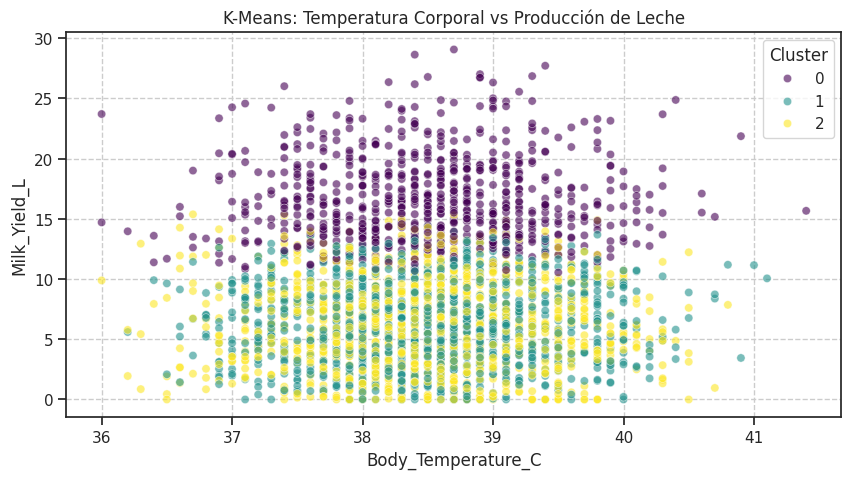

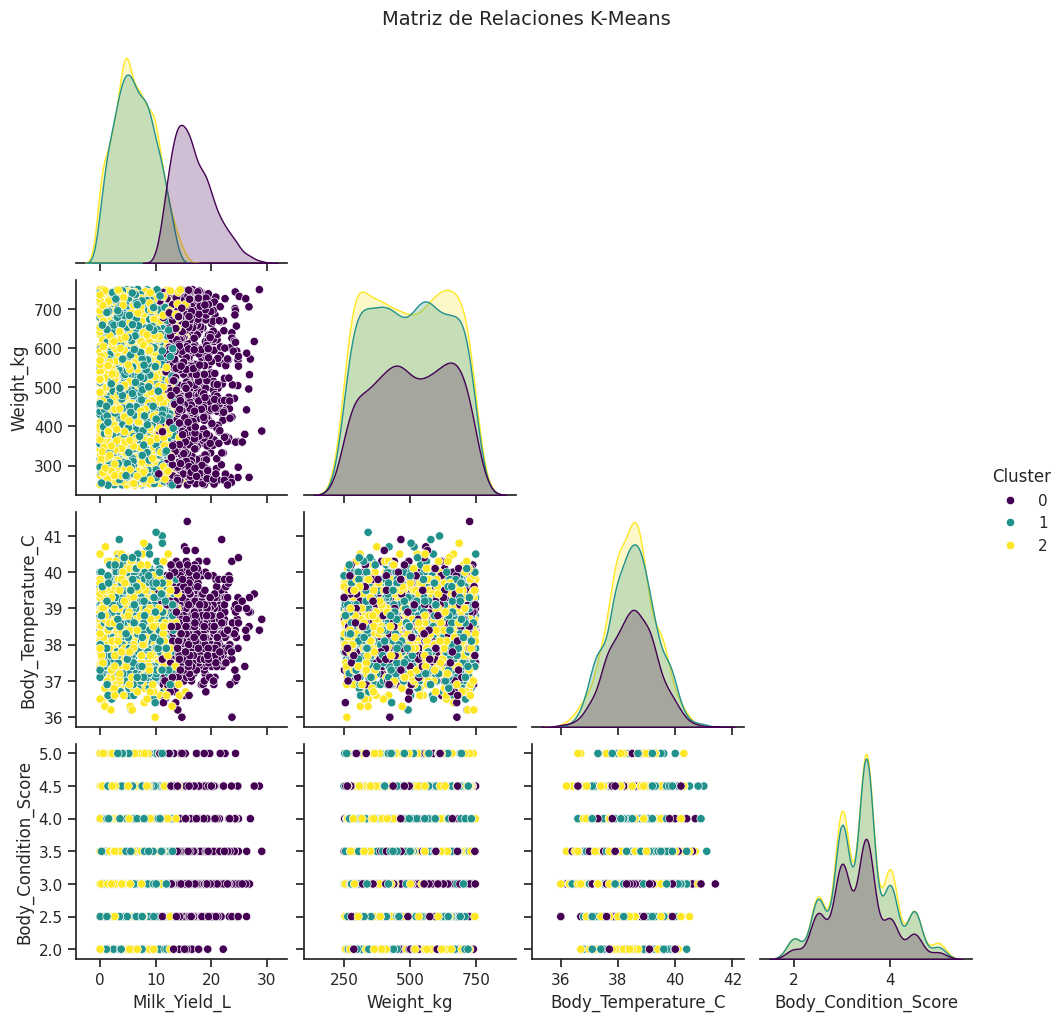

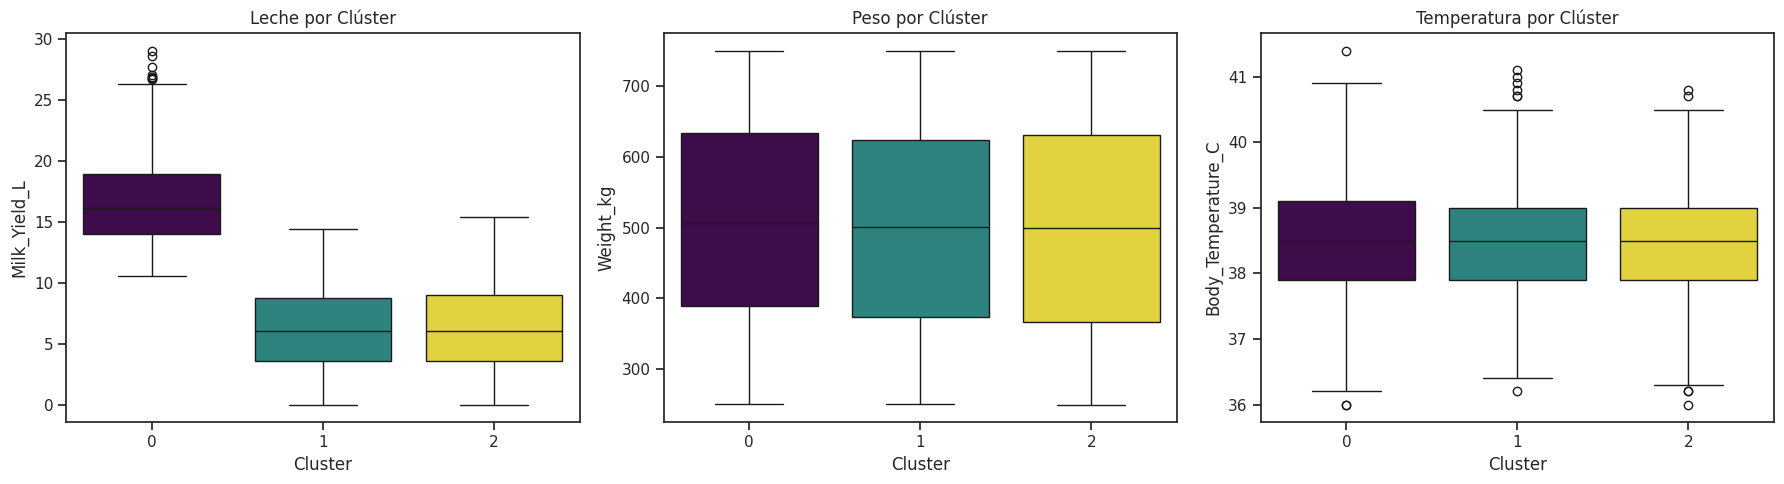


--- Distribución de Clústeres DBSCAN ---
DB_Cluster
 0    9834
-1     166
Name: count, dtype: int64


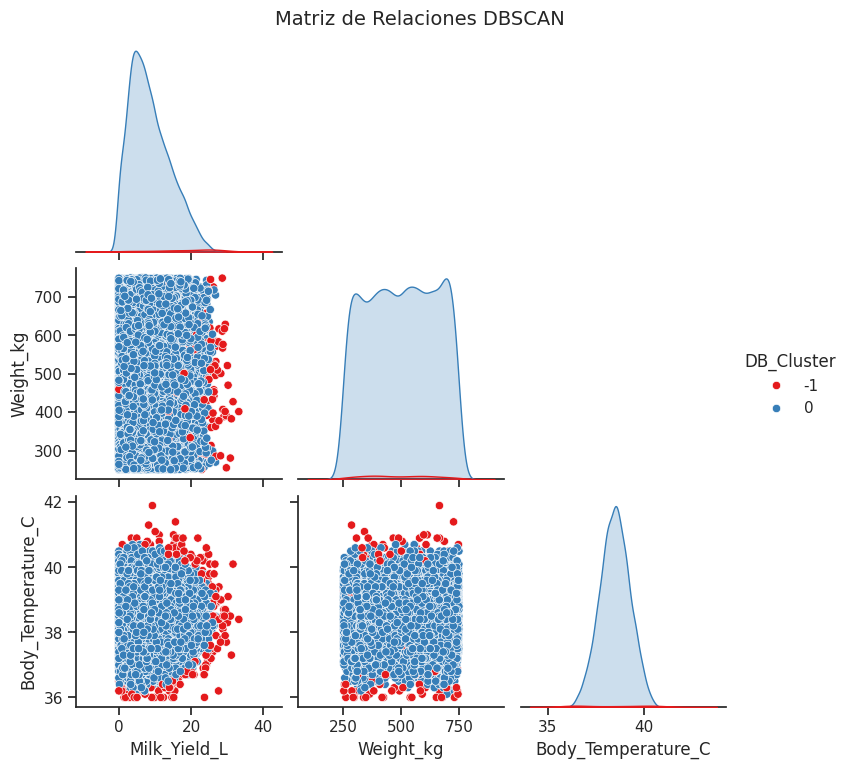

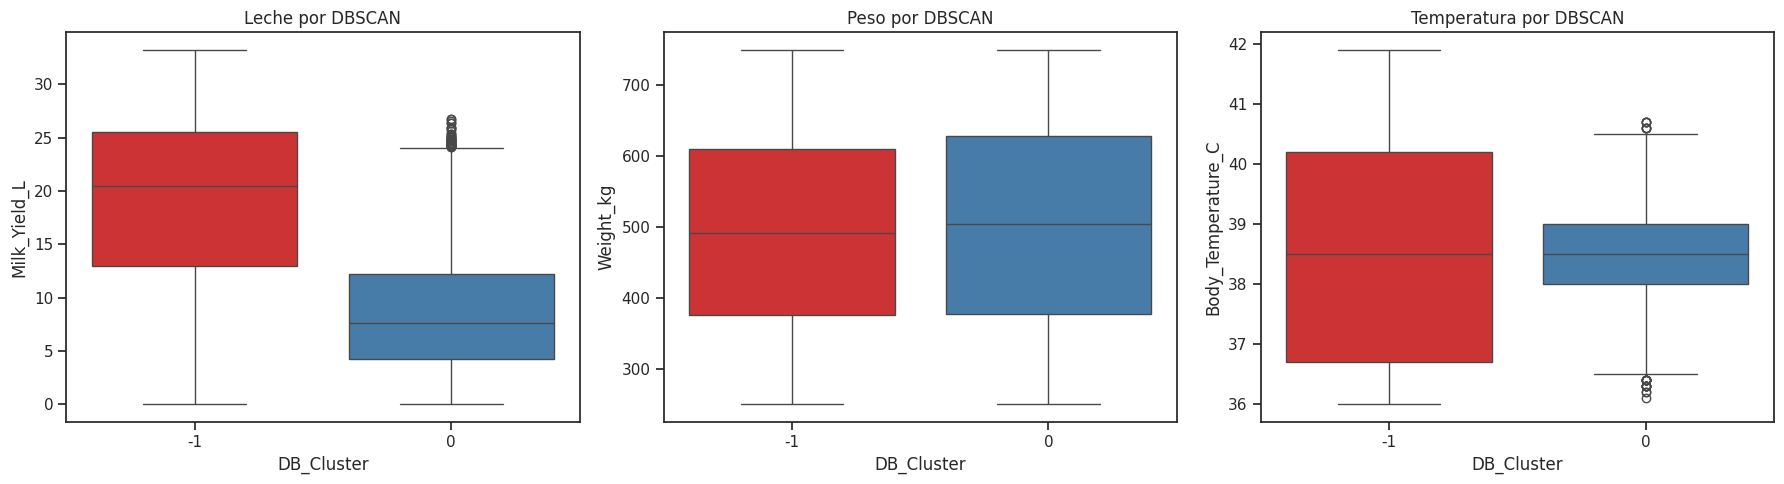

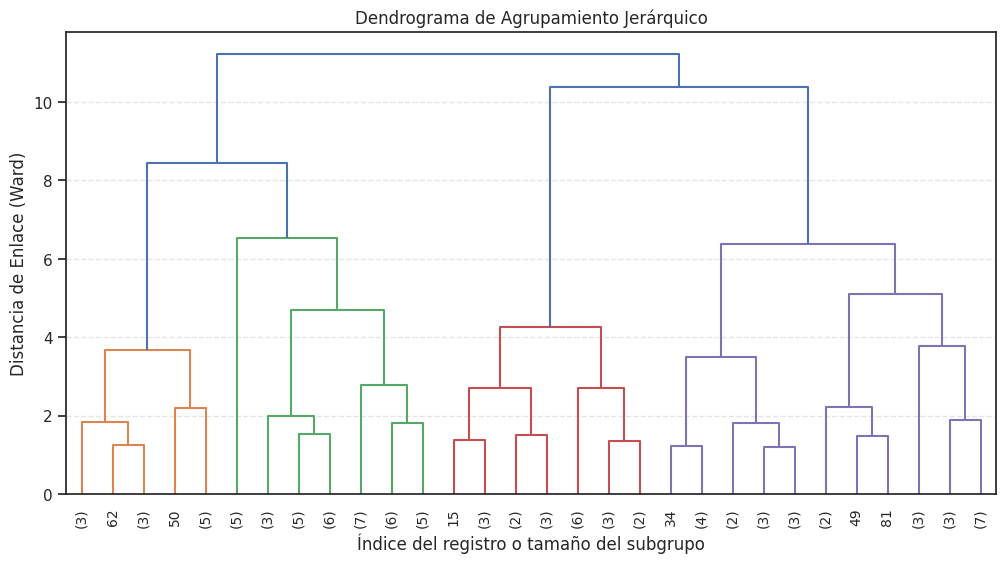


--- Distribución de Clústeres Jerárquicos ---
Agg_Cluster
1    4087
0    3466
2    2447
Name: count, dtype: int64


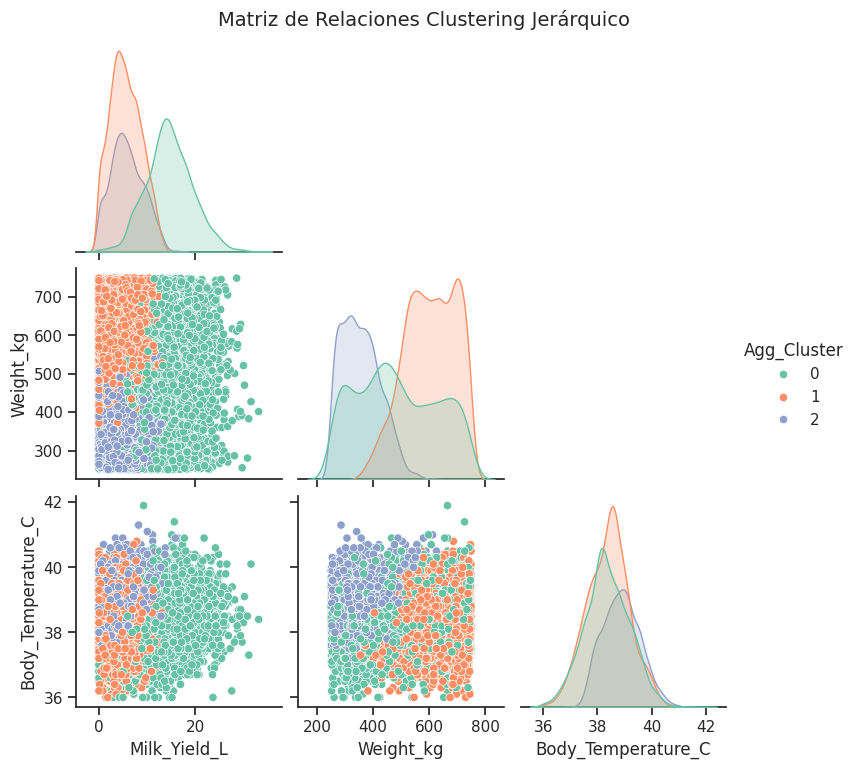

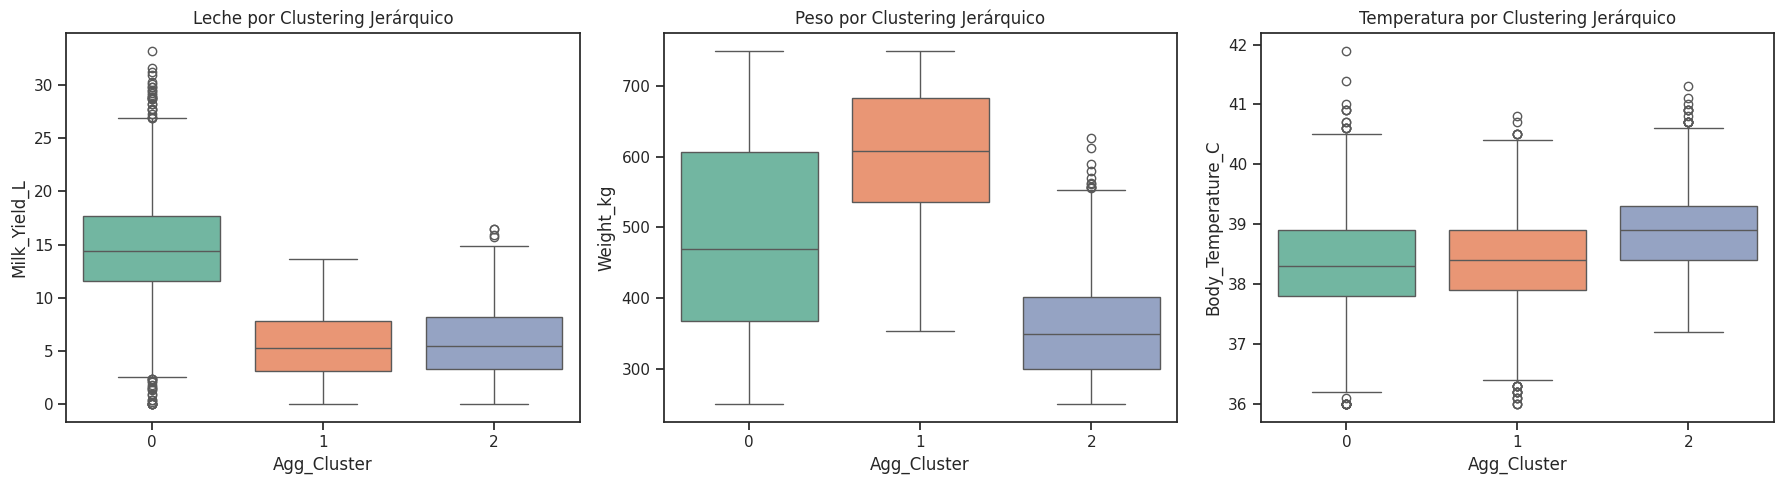

In [ ]:
# ==============================================================================
# SECCIÓN VACAS - ANÁLISIS COMPLETO DE CLUSTERING 
# ==============================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage

# Configuración de estilos visuales para los gráficos
sns.set_theme(style="ticks")

# ------------------------------------------------------------------------------
# 1. CARGA DE DATOS DESDE GOOGLE DRIVE
# ------------------------------------------------------------------------------
try:
    if not os.path.exists('/content/drive'):
        print("Intentando montar Google Drive. Por favor, acepta los permisos en la ventana emergente si aparece...")
        drive.mount('/content/drive')
except Exception as e:
    print(f"No se pudo montar Google Drive automáticamente ({e}).")
    print("Por favor, haz clic en el icono de carpeta de la izquierda en Colab y presiona el botón 'Montar Drive' para hacerlo de forma manual.\n")

def buscar_archivo(nombre_objetivo, ruta_inicio='/content/drive/MyDrive'):
    print("Buscando el archivo en Google Drive...")
    rutas_encontradas = []
    for raiz, dirs, archivos in os.walk(ruta_inicio):
        for archivo in archivos:
            if nombre_objetivo.lower() in archivo.lower():
                rutas_encontradas.append(os.path.join(raiz, archivo))
    return rutas_encontradas

nombre_archivo_nuevo = "global_cattle_disease_detection_dataset"
rutas = buscar_archivo(nombre_archivo_nuevo)

if rutas:
    csv_reales = [r for r in rutas if not r.endswith('.gsheet')]
    if csv_reales:
        ruta_a_cargar = csv_reales[0]
        try:
            df_vacas = pd.read_csv(ruta_a_cargar)
            print(f"\n¡Dataset cargado con éxito! Dimensiones: {df_vacas.shape[0]} filas, {df_vacas.shape[1]} columnas.\n")
        except Exception as e:
            print(f"Error al cargar el archivo CSV: {e}")
    else:
        print("Se encontró el archivo pero corresponde a un formato no compatible (.gsheet).")
else:
    print("No se encontró el archivo del dataset en Google Drive. Verifica que esté subido y que Drive esté montado correctamente.")

# El resto del código de modelado y segmentación se ejecutará si 'df_vacas' está definido de forma correcta:
if 'df_vacas' in locals():
    # ------------------------------------------------------------------------------
    # 2. SEGMENTACIÓN CON K-MEANS
    # ------------------------------------------------------------------------------
    columnas_numericas = [
        'Age_Months', 'Weight_kg', 'Milk_Yield_L',
        'Body_Temperature_C', 'Heart_Rate_bpm',
        'Respiratory_Rate', 'Body_Condition_Score'
    ]
    X_kmeans = df_vacas[columnas_numericas].copy()

    scaler_km = StandardScaler()
    X_scaled = scaler_km.fit_transform(X_kmeans)

    n_clusters = 3
    k_means_model = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    df_vacas['Cluster'] = k_means_model.fit_predict(X_scaled)

    print("\n--- Distribución de Clústeres K-Means ---")
    print(df_vacas['Cluster'].value_counts())

    # Gráficas de K-Means (Muestra para optimización)
    df_sample = df_vacas.sample(3000, random_state=42)

    # Relación Temperatura vs Leche
    plt.figure(figsize=(10, 5))
    sns.scatterplot(data=df_sample, x='Body_Temperature_C', y='Milk_Yield_L', hue='Cluster', palette='viridis', alpha=0.6)
    plt.title('K-Means: Temperatura Corporal vs Producción de Leche')
    plt.grid(True, linestyle='--')
    plt.show()

    # Pairplot y Boxplots K-Means
    variables_clave = ['Milk_Yield_L', 'Weight_kg', 'Body_Temperature_C', 'Body_Condition_Score', 'Cluster']
    g_km = sns.pairplot(df_sample[variables_clave], hue='Cluster', palette='viridis', corner=True, diag_kind='kde')
    g_km.fig.suptitle('Matriz de Relaciones K-Means', y=1.02, fontsize=14)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.boxplot(data=df_sample, x='Cluster', y='Milk_Yield_L', ax=axes[0], palette='viridis', hue='Cluster', legend=False)
    axes[0].set_title('Leche por Clúster')
    sns.boxplot(data=df_sample, x='Cluster', y='Weight_kg', ax=axes[1], palette='viridis', hue='Cluster', legend=False)
    axes[1].set_title('Peso por Clúster')
    sns.boxplot(data=df_sample, x='Cluster', y='Body_Temperature_C', ax=axes[2], palette='viridis', hue='Cluster', legend=False)
    axes[2].set_title('Temperatura por Clúster')
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------------------------
    # 3. SEGMENTACIÓN CON DBSCAN
    # ------------------------------------------------------------------------------
    df_dbscan_sample = df_vacas.sample(10000, random_state=42).copy()
    columnas_dbscan = ['Weight_kg', 'Milk_Yield_L', 'Body_Temperature_C']
    X_db = df_dbscan_sample[columnas_dbscan]

    scaler_db = StandardScaler()
    X_db_scaled = scaler_db.fit_transform(X_db)

    dbscan = DBSCAN(eps=0.5, min_samples=15)
    df_dbscan_sample['DB_Cluster'] = dbscan.fit_predict(X_db_scaled)

    print("\n--- Distribución de Clústeres DBSCAN ---")
    print(df_dbscan_sample['DB_Cluster'].value_counts())

    # Pairplot y Boxplots DBSCAN
    variables_dbscan_plot = ['Milk_Yield_L', 'Weight_kg', 'Body_Temperature_C', 'DB_Cluster']
    g_db = sns.pairplot(df_dbscan_sample[variables_dbscan_plot], hue='DB_Cluster', palette='Set1', corner=True, diag_kind='kde')
    g_db.fig.suptitle('Matriz de Relaciones DBSCAN', y=1.02, fontsize=14)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.boxplot(data=df_dbscan_sample, x='DB_Cluster', y='Milk_Yield_L', ax=axes[0], palette='Set1', hue='DB_Cluster', legend=False)
    axes[0].set_title('Leche por DBSCAN')
    sns.boxplot(data=df_dbscan_sample, x='DB_Cluster', y='Weight_kg', ax=axes[1], palette='Set1', hue='DB_Cluster', legend=False)
    axes[1].set_title('Peso por DBSCAN')
    sns.boxplot(data=df_dbscan_sample, x='DB_Cluster', y='Body_Temperature_C', ax=axes[2], palette='Set1', hue='DB_Cluster', legend=False)
    axes[2].set_title('Temperatura por DBSCAN')
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------------------------------
    # 4. CLUSTERING JERÁRQUICO AGLOMERATIVO
    # ------------------------------------------------------------------------------
    df_agg_sample = df_vacas.sample(10000, random_state=42).copy()
    columnas_agg = ['Weight_kg', 'Milk_Yield_L', 'Body_Temperature_C']
    X_agg = df_agg_sample[columnas_agg]

    scaler_agg = StandardScaler()
    X_agg_scaled = scaler_agg.fit_transform(X_agg)

    # Dendrograma (Muestra reducida a 100 para legibilidad)
    plt.figure(figsize=(12, 6))
    X_dendro_sample = X_agg_scaled[np.random.choice(X_agg_scaled.shape[0], 100, replace=False)]
    enlaces = linkage(X_dendro_sample, method='ward')
    dendrogram(enlaces, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=10)
    plt.title('Dendrograma de Agrupamiento Jerárquico')
    plt.xlabel('Índice del registro o tamaño del subgrupo')
    plt.ylabel('Distancia de Enlace (Ward)')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

    # Modelo jerárquico
    n_clusters_agg = 3
    agg_clustering = AgglomerativeClustering(n_clusters=n_clusters_agg, linkage='ward')
    df_agg_sample['Agg_Cluster'] = agg_clustering.fit_predict(X_agg_scaled)

    print("\n--- Distribución de Clústeres Jerárquicos ---")
    print(df_agg_sample['Agg_Cluster'].value_counts())

    # Pairplot y Boxplots Clustering Jerárquico
    variables_agg_plot = ['Milk_Yield_L', 'Weight_kg', 'Body_Temperature_C', 'Agg_Cluster']
    g_agg = sns.pairplot(df_agg_sample[variables_agg_plot], hue='Agg_Cluster', palette='Set2', corner=True, diag_kind='kde')
    g_agg.fig.suptitle('Matriz de Relaciones Clustering Jerárquico', y=1.02, fontsize=14)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    sns.boxplot(data=df_agg_sample, x='Agg_Cluster', y='Milk_Yield_L', ax=axes[0], palette='Set2', hue='Agg_Cluster', legend=False)
    axes[0].set_title('Leche por Clustering Jerárquico')
    sns.boxplot(data=df_agg_sample, x='Agg_Cluster', y='Weight_kg', ax=axes[1], palette='Set2', hue='Agg_Cluster', legend=False)
    axes[1].set_title('Peso por Clustering Jerárquico')
    sns.boxplot(data=df_agg_sample, x='Agg_Cluster', y='Body_Temperature_C', ax=axes[2], palette='Set2', hue='Agg_Cluster', legend=False)
    axes[2].set_title('Temperatura por Clustering Jerárquico')
    plt.tight_layout()
    plt.show()
else:
    print("No se puede ejecutar el análisis de clustering porque no se cargó el dataset.")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful



### Limitaciones que deben declararse
- Los resultados dependen de este dataset y de la estrategia de división.
- `Previous_Week_Avg_Yield` puede ser muy informativa, pero solo es válida si se conoce antes de estimar la producción objetivo.
- Las relaciones encontradas son predictivas, no necesariamente causales.
- Las categorías bajo/medio/alto son una simplificación operacional basada en cuantiles de entrenamiento; no son categorías clínicas o productivas oficiales.
- La fuente Kaggle y el artículo original deben citarse en la presentación; no atribuyas al artículo decisiones que no hayas verificado.